# Синтетический эксперимент — этап 1

## Цели и следующий этап

Готовим данные для будущего A/B-теста, сравниваем четыре модели атрибуции для предварительного выбора на реальных данных и проверяем работоспособность платформы. Начинаем с выборки и четырёх сценариев, затем сверяем расчёты и отчёт бота. Спецификация и первый прогон каждого сценария — в [пилотном ноутбуке](scenario_pilot.ipynb).

Один воспроизводимый генератор, полная база для бота, баланс выручки и сравнение размещений одинакового возраста.

**Это проверка механики, а не готовая рекомендация бюджета.** Исторический профиль продаж используется как сценарий спроса; он не объявляется естественным спросом. Модель календарных событий, взаимодействия категорий и контрфактический эффект рекламы — следующий этап.

Старая рабочая версия сохранена в `archive/synthetic_attribution_experiment_updated_before_stage1.ipynb`. Повторяющиеся генераторы, настройки и fallback-код из активного файла удалены. Эвристика `organic_adjusted` исключена из рейтинга: коэффициенты не оценены, а прежняя реализация теряла остаток выручки. Покупки без подходящих касаний остаются в органике.


## 1. Запуск из чистого ядра

Локально: установите `requirements-notebooks.txt`, откройте ноутбук с Python из `.venv312` и выполните Restart Kernel → Run All. Рабочая папка — корень проекта или `notebooks/`.

В Colab нужны **актуальные изменения проекта**, включая `src/experiments/synthetic.py`. До публикации локальных изменений в GitHub загрузите проект целиком. Старый код из другого репозитория автоматически не подставляется.


In [1]:
from pathlib import Path
import sys
import subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/marketing_attribution_system")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "https://github.com/valentinesvev/marketing_attribution_system.git", str(ROOT)], check=True)
    if not (ROOT / "src/experiments/synthetic.py").exists():
        raise RuntimeError("Нужна актуальная версия проекта с модулем этапа 1. Загрузите локальный проект или опубликуйте изменения.")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements-notebooks.txt")], check=True)
else:
    ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/experiments/synthetic.py").exists()), None)
    if ROOT is None:
        raise RuntimeError("Запустите ноутбук из каталога проекта или notebooks/.")
sys.path.insert(0, str(ROOT / "src"))
print("Project:", ROOT)


Project: /home/valentina/marketing_attribution_system


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from core import attribution
from experiments.synthetic import (
    Config, load_history, build_placements, simulate, validate_simulation,
    allocate, evaluate_horizons, score_horizons, run_many, export_database,
)

CONFIG = Config(seed=42, n_users=1000, n_runs=30)
HISTORY_PATH = ROOT / "data/raw/base.csv"
print(CONFIG)


Config(seed=42, n_users=1000, n_runs=30, attribution_days=30, horizons=(7, 14, 30), base_daily_purchase=0.018, organic_visit_probability=0.28, view_probability=0.72, propensity_sigma=0.45, propensity_min=0.45, propensity_max=2.4, decay_tau_days=7.0, min_repeat_days=3.0, max_orders=2, acquiring_rate=0.03, demand_extension=1.0)


## 2. Что берём из истории

Строки одного покупателя с одинаковым временем объединяются в заказ. Используем распределение чеков, долю повторных покупателей как параметр сценария и сглаженную динамику числа заказов.

В исторических продажах могут быть эффекты рекламы и событий. **Эта линия не является оценкой органики.** За пределами истории индекс спроса равен `CONFIG.demand_extension` (по умолчанию 1 — среднее), без повторения пиков и без молчаливого продолжения последнего дня. Это явное техническое допущение для наблюдения D30 поздних размещений.


,metric,value
0,Historical orders,628.000000
1,Historical repeat buyers share,0.033003
2,Median order amount,8950.000000


,placement_id,channel,campaign_name,placement_type,creative,post_category,discount_value,cost,publication_time,reach_probability,daily_lift
0,a,tg_ml_jobs,stage1,external,creative_a,sale,0,70000.0,2026-08-07,0.24,0.0060
1,b,tg_data_jobs,stage1,external,creative_b,native,0,55000.0,2026-08-17,0.22,0.0048
2,c,tg_students,stage1,external,creative_c,discount,0,40000.0,2026-08-27,0.18,0.0035
3,d,tg_career,stage1,external,creative_d,content,0,40000.0,2026-09-03,0.34,0.0015


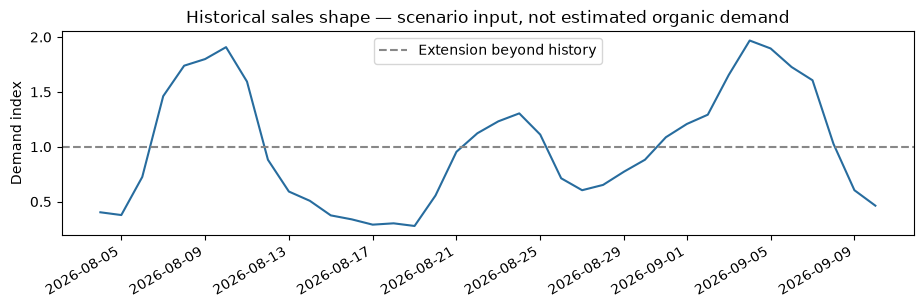

In [3]:
history = load_history(HISTORY_PATH)
placements = build_placements(history["demand"].index.min())
display(pd.DataFrame({"metric": ["Historical orders", "Historical repeat buyers share", "Median order amount"],
                      "value": [len(history["orders"]), history["repeat_rate"], history["orders"].amount.median()]}))
display(placements)
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(history["demand"].index, history["demand"].values, color="#276c9e")
ax.axhline(CONFIG.demand_extension, color="#888888", linestyle="--", label="Extension beyond history")
ax.set(title="Historical sales shape — scenario input, not estimated organic demand", ylabel="Demand index")
ax.legend(); fig.autofmt_xdate(); plt.show()


## 2.1. Календарь: известные внешние события

Два события заданы вручную как **контекст, не доказательство причинности**:
- 8 августа 2026 — старт экзаменов в магистратуры;
- 5 сентября 2026 — отбор / стажировка Т-Банк.

Проверяем расположение продаж относительно этих дат. Пик может начаться заранее; эффект, если он есть, может различаться по курсам. Пока известны только опорные даты: начало подготовки, длительность отбора, затронутые продукты и сила влияния требуют уточнения.

Ниже — описательные графики и непересекающиеся интервалы: 7 дней до события, день события и 7 дней после. Для неполных интервалов показываем доступное число дней; сумма за 4 дня не сопоставляется напрямую с суммой за 7 дней. Средние за день тоже не устраняют календарные различия и влияние рекламы. Крайние даты выгрузки могут быть неполными днями.

Календарь пока не меняет вероятности покупок: историческая линия уже включает наблюдавшиеся пики, поэтому дополнительный множитель мог бы учесть их дважды.

### Что исторические данные не позволяют установить

По доступной истории нельзя сказать, какие всплески и в какой мере объясняются естественным спросом, рекламными публикациями, запуском продукта или их совместным действием. Совпадение пика с календарным событием или публикацией — контекст и гипотеза, а не оценка причинного эффекта. В частности, 22 августа опубликован запуск линейки ПРО: соседний пик нельзя автоматически считать ни органическим, ни целиком рекламным.

Чтобы измерить дополнительный эффект конкретной рекламы, нужен A/B-тест: сопоставимые аудитории случайно распределяются в группу с рекламным воздействием и контрольную группу без него, наблюдаются одновременно и за одинаковый срок. Разница результатов оценивается с неопределённостью. При нескольких рекламных воздействиях нужно заранее определить, какое именно воздействие проверяем, и учитывать пересечение аудиторий. Календарные события при этом действуют на обе группы; такой тест измеряет эффект проверяемой рекламы в данном контексте, а не автоматически объясняет все исторические пики.

Поэтому в эксперименте естественный спрос и рекламный эффект задаются как явные предположения сценария. Проверяем несколько вариантов их соотношения, не объявляя исторический профиль продаж чистой органикой. Регрессия по календарю, просмотрам и подписчикам может помогать прогнозировать наблюдаемые продажи, но сама по себе не заменяет контрольную группу для причинной оценки.


,event_date,event_name,source,causal_effect_estimated
0,2026-08-08,Старт экзаменов в магистратуры,manual,False
1,2026-09-05,Отбор / стажировка Т-Банк,manual,False


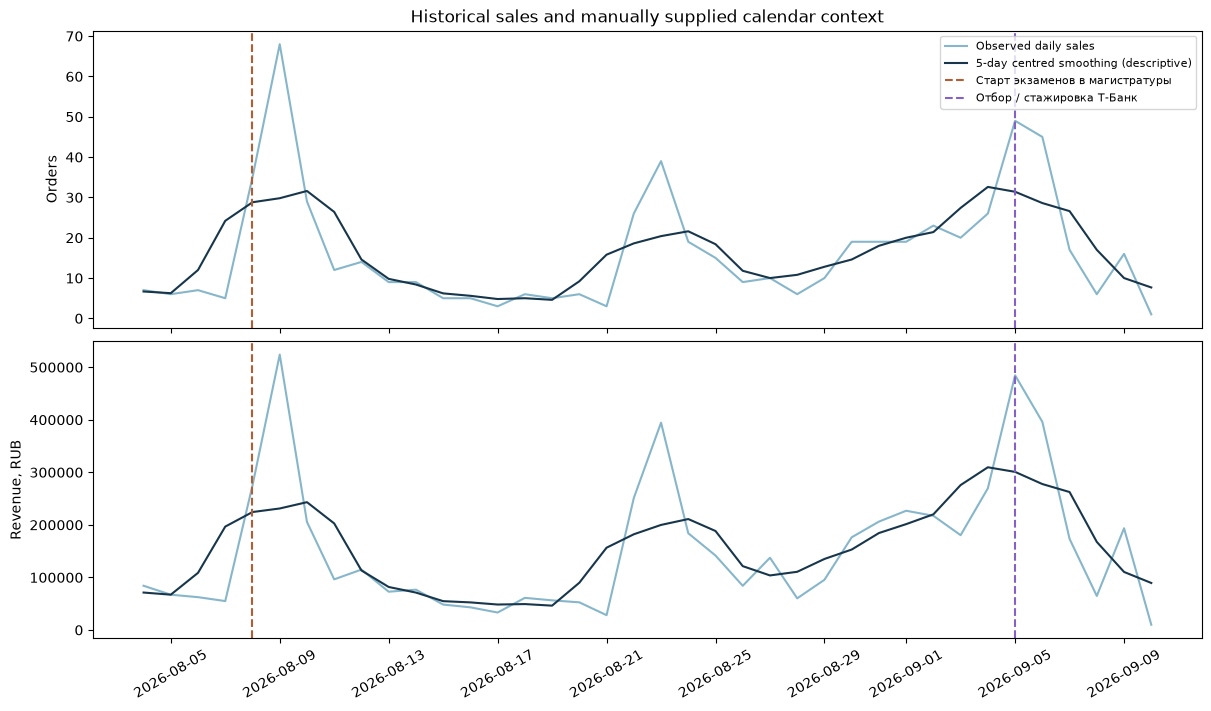

,event,window,observed_days,expected_days,complete,orders,revenue,orders_per_observed_day,revenue_per_observed_day
0,Старт экзаменов в магистратуры,before_7d,4,7,False,25,268680.00,6.25,67170.00
1,Старт экзаменов в магистратуры,event_day,1,1,True,35,275015.00,35.00,275015.00
2,Старт экзаменов в магистратуры,after_7d,7,7,True,146,1138786.67,20.86,162683.81
3,Отбор / стажировка Т-Банк,before_7d,7,7,True,136,1372198.00,19.43,196028.29
4,Отбор / стажировка Т-Банк,event_day,1,1,True,49,484684.00,49.00,484684.00
5,Отбор / стажировка Т-Банк,after_7d,5,7,False,85,837750.00,17.00,167550.00


In [4]:
# Известные внешние события — контекст, не доказательство причинности.
events_calendar = {
    pd.Timestamp("2026-08-08"): "Старт экзаменов\nв магистратуры",
    pd.Timestamp("2026-09-05"): "Отбор / стажировка\nТ-Банк",
}
calendar = pd.DataFrame([
    {"event_date": day, "event_name": title.replace("\n", " "), "source": "manual", "causal_effect_estimated": False}
    for day, title in events_calendar.items()
])
display(calendar)
historical_orders = history["orders"].copy()
daily_history = historical_orders.groupby(historical_orders.ts.dt.normalize()).agg(
    orders=("amount", "size"), revenue=("amount", "sum")
).asfreq("D", fill_value=0)
calendar_fig, calendar_axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, constrained_layout=True)
for ax, metric, label in zip(calendar_axes, ["orders", "revenue"], ["Orders", "Revenue, RUB"]):
    ax.plot(daily_history.index, daily_history[metric], color="#247ba0", alpha=.55, label="Observed daily sales")
    ax.plot(daily_history.index, daily_history[metric].rolling(5, center=True, min_periods=1).mean(), color="#18364b", label="5-day centred smoothing (descriptive)")
    for i, (date, title) in enumerate(events_calendar.items()):
        ax.axvline(date, color=["#b45c33", "#8561c5"][i], linestyle="--", label=title.replace("\n", " "))
    ax.set_ylabel(label)
calendar_axes[0].set_title("Historical sales and manually supplied calendar context")
calendar_axes[0].legend(fontsize=8, loc="upper right")
calendar_axes[1].tick_params(axis="x", rotation=30)
plt.show()
windows = []
for date, title in events_calendar.items():
    for name, left, right in [("before_7d", -7, 0), ("event_day", 0, 1), ("after_7d", 1, 8)]:
        expected = right-left
        sample = daily_history.loc[(daily_history.index >= date+pd.Timedelta(days=left)) & (daily_history.index < date+pd.Timedelta(days=right))]
        windows.append(dict(event=title.replace("\n", " "), window=name,
            observed_days=len(sample), expected_days=expected, complete=len(sample)==expected,
            orders=int(sample.orders.sum()), revenue=float(sample.revenue.sum()),
            orders_per_observed_day=sample.orders.mean(), revenue_per_observed_day=sample.revenue.mean()))
calendar_windows = pd.DataFrame(windows)
display(calendar_windows.round(2))


## 2.2. Идеи будущей модели спроса

План сбора просмотров, подписок, календаря и проверки будущей регрессии перенесён в [единый файл планов](../future_improvements.md). Определения и ограничения показателей — в [metrics.md](../metrics.md). Регрессия пока не реализована; исторические ряды просмотров и подписок отсутствуют.


## 3. Одна генерация и проверки

Время потенциальной покупки выбирается **до** отбора рекламных касаний. Влияние из будущего запрещено. Для повторной покупки учитываются только касания после предыдущей; минимальный интервал также проверяется.

Создаются все семь исходных таблиц бота. Заявка привязывается к касанию до неё, заказ — к заявке. Позиции заказа сходятся с его суммой. Заявки пока создаются только для покупок, поэтому конверсию неоплаченных заявок не моделируем. Категории постов пока только метаданные, механизм затухания общий; `decay_tau_days` — время уменьшения эффекта в e раз, не период полураспада.


In [5]:
simulation = simulate(history, placements, CONFIG)
frames = simulation["frames"]
checks = validate_simulation(simulation)
print(checks)
print("Observation interval [start, end):", simulation["start"], simulation["end"])
print("Model set:", attribution.MODELS)


{'users': 1000, 'touches': 1282, 'orders': 729, 'revenue': 7029571.0, 'checks': 'passed'}
Observation interval [start, end): 2026-08-04 00:00:00 2026-10-03 00:00:00
Model set: ('last', 'first', 'linear', 'position')


## 4. Покупки без касаний и баланс денег

Здесь различаем два признака:
- **органика по правилам атрибуции:** нет подходящего рекламного касания перед покупкой;
- **organic / ad_tagged в генераторе:** из какой ветки симуляции возникла покупка.

Покупка может иметь рекламное касание, но возникнуть из органической ветки. Четыре модели этого не знают. Метка `ad_tagged` — диагностический эталон механизма, **не измеренный контрфактический прирост**.


In [6]:
orders = frames["fact_order"]
labels = frames["order_truth"]
summary = pd.DataFrame({"metric": ["Users", "Touches", "Buyers", "Orders", "Revenue", "Organic mechanism orders", "Ad-tagged mechanism orders"],
                        "value": [len(frames["dim_user"]), len(frames["fact_touch"]), orders.user_id_hash.nunique(),
                                  len(orders), orders.amount.sum(), labels.mechanism.eq("organic").sum(), labels.mechanism.eq("ad_tagged").sum()]})
display(summary)
allocations = {model: allocate(simulation, model) for model in attribution.MODELS}
balance = pd.DataFrame([dict(model=model,
    observed_revenue=orders.amount.sum(),
    paid_credit=att.loc[att.placement_id.notna(), "attributed_revenue"].sum(),
    organic_credit=att.loc[att.placement_id.isna(), "attributed_revenue"].sum(),
    balance_error=att.attributed_revenue.sum()-orders.amount.sum())
    for model, att in allocations.items()])
display(balance.round(2))
assert np.allclose(balance.balance_error, 0)


,metric,value
0,Users,1000.0
1,Touches,1282.0
2,Buyers,651.0
3,Orders,729.0
4,Revenue,7029571.0
5,Organic mechanism orders,708.0
6,Ad-tagged mechanism orders,21.0


,model,observed_revenue,paid_credit,organic_credit,balance_error
0,last,7029571.0,2942670.0,4086901.0,0.0
1,first,7029571.0,2942670.0,4086901.0,0.0
2,linear,7029571.0,2942670.0,4086901.0,0.0
3,position,7029571.0,2942670.0,4086901.0,0.0


## 5. Сравниваем одинаковый возраст: D7 / D14 / D30

Для каждого размещения считаем покупки в интервале `[публикация, публикация + H дней)`. Основной горизонт — D30. Симуляция продолжается до созревания последнего поста.

Окно атрибуции `attribution_days` отсчитывается назад от покупки и независимо от горизонта оценки H. Сначала рассчитываем атрибуцию с полной предысторией, затем ограничиваем результат возрастом поста. Исключённые доли не перераспределяем другим размещениям. Нельзя складывать строки D7, D14 и D30: это пересекающиеся интервалы, а не разные продажи.

Если на дату отчёта пост ещё слишком молодой, итоговые показатели H получают `NaN`, а не ноль. Равный возраст исправляет разную длину наблюдения, **но не устраняет различия календарного спроса и аудитории**.


In [7]:
horizons = evaluate_horizons(simulation)
d30 = horizons[horizons.horizon_days.eq(30)]
display(d30[["placement_id", "model", "observed_days", "mature", "cost", "attributed_revenue", "tagged_revenue", "attributed_romi_pct", "tagged_romi_pct"]].round(2))
# Ранний срез: у новых постов ещё нет завершённого D30.
early = evaluate_horizons(simulation, as_of=history["demand"].index.max()+pd.Timedelta(days=1))
display(early[early.horizon_days.eq(30) & early.model.eq("last")][["placement_id", "observed_days", "mature", "attributed_romi_pct"]])


,placement_id,model,observed_days,mature,cost,attributed_revenue,tagged_revenue,attributed_romi_pct,tagged_romi_pct
8,a,last,30.0,True,70000.0,1000418.0,64920.0,1329.17,-7.26
9,a,first,30.0,True,70000.0,1125618.0,64920.0,1508.03,-7.26
10,a,linear,30.0,True,70000.0,1063018.0,64920.0,1418.60,-7.26
11,a,position,30.0,True,70000.0,1063018.0,64920.0,1418.60,-7.26
20,b,last,30.0,True,55000.0,466453.0,56930.0,748.10,3.51
21,b,first,30.0,True,55000.0,548993.0,56930.0,898.17,3.51
22,b,linear,30.0,True,55000.0,505073.0,56930.0,818.31,3.51
23,b,position,30.0,True,55000.0,506133.0,56930.0,820.24,3.51
32,c,last,30.0,True,40000.0,388450.0,33380.0,871.12,-16.55
33,c,first,30.0,True,40000.0,401770.0,33380.0,904.42,-16.55


,placement_id,observed_days,mature,attributed_romi_pct
8,a,30.0,True,1329.168571
20,b,25.0,False,NaN
32,c,15.0,False,NaN
44,d,8.0,False,NaN


## 6. Один итоговый рисунок

Сверху — баланс выручки и сопоставимые D30. Снизу — как меняется ROMI по возрасту поста и насколько оценки расходятся с меткой генератора. Расхождение показывает ограничение правила атрибуции; это не тест доказанного причинного эффекта.


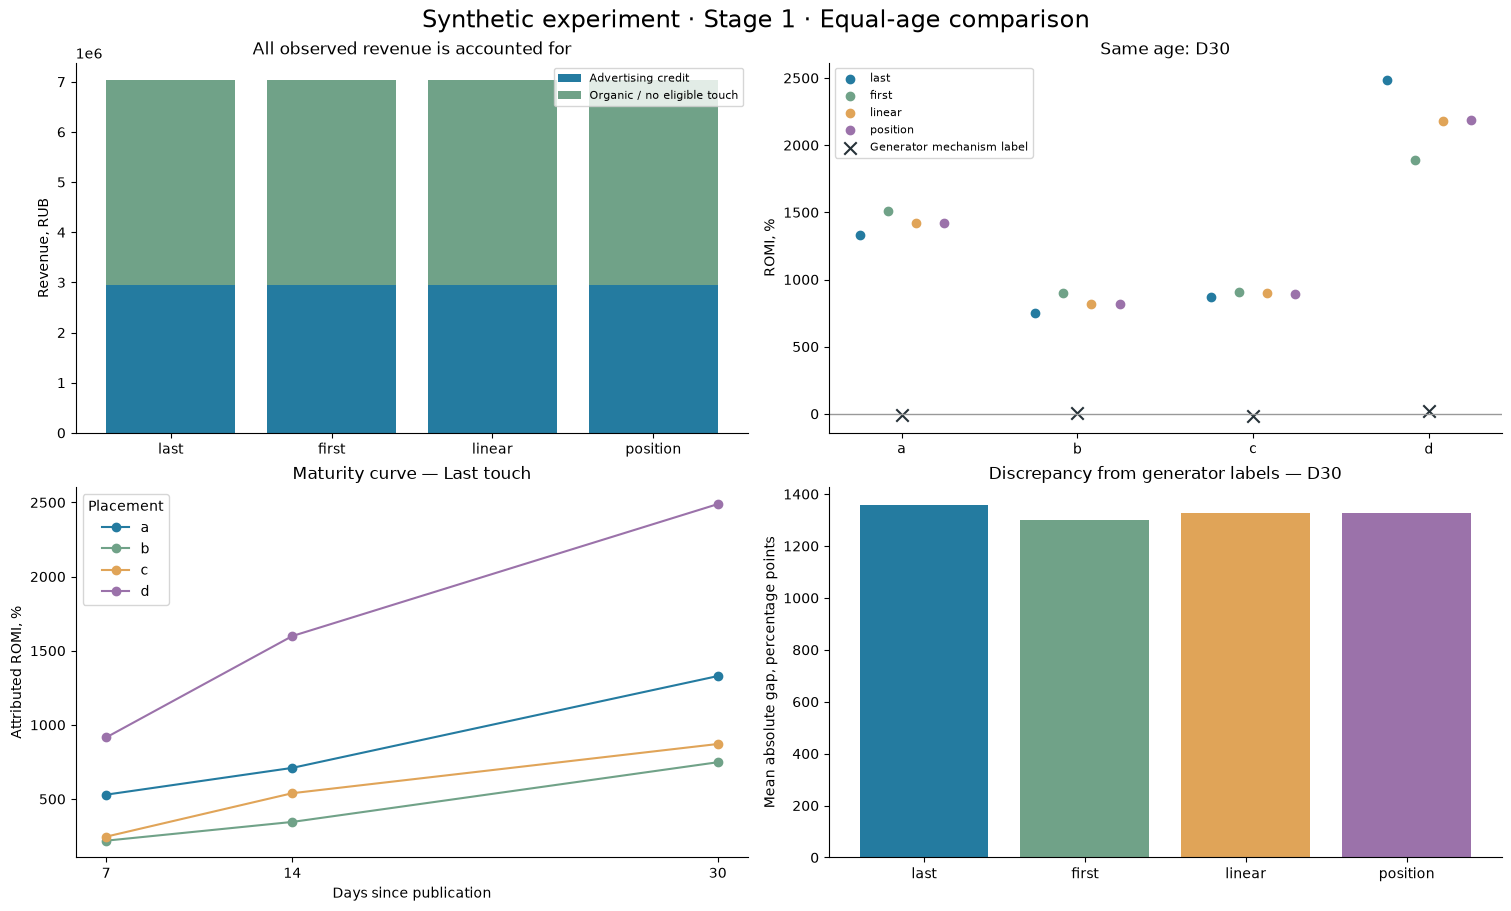

In [8]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
colors = ["#247ba0", "#70a288", "#e0a458", "#9b72aa"]
axes[0, 0].bar(balance.model, balance.paid_credit, color="#247ba0", label="Advertising credit")
axes[0, 0].bar(balance.model, balance.organic_credit, bottom=balance.paid_credit, color="#70a288", label="Organic / no eligible touch")
axes[0, 0].set(title="All observed revenue is accounted for", ylabel="Revenue, RUB")
axes[0, 0].legend(fontsize=8)
ids = placements.placement_id.tolist()
x = np.arange(len(ids))
for shift, model, color in zip(np.linspace(-.24, .24, 4), attribution.MODELS, colors):
    data = d30[d30.model.eq(model)].set_index("placement_id").reindex(ids)
    axes[0, 1].scatter(x+shift, data.attributed_romi_pct, label=model, color=color)
tagged = d30[d30.model.eq("last")].set_index("placement_id").reindex(ids)
axes[0, 1].scatter(x, tagged.tagged_romi_pct, color="#263238", marker="x", s=80, label="Generator mechanism label")
axes[0, 1].axhline(0, color="#999", linewidth=1)
axes[0, 1].set(xticks=x, xticklabels=ids, title="Same age: D30", ylabel="ROMI, %")
axes[0, 1].legend(fontsize=8)
for pid, color in zip(ids, colors):
    data = horizons[horizons.model.eq("last") & horizons.placement_id.eq(pid)].sort_values("horizon_days")
    axes[1, 0].plot(data.horizon_days, data.attributed_romi_pct, marker="o", label=pid, color=color)
axes[1, 0].set(title="Maturity curve — Last touch", xlabel="Days since publication", ylabel="Attributed ROMI, %", xticks=CONFIG.horizons)
axes[1, 0].legend(title="Placement")
scores = score_horizons(horizons)
scores30 = scores[scores.horizon_days.eq(30)].set_index("model").reindex(attribution.MODELS)
axes[1, 1].bar(scores30.index, scores30.mae_pp, color=colors)
axes[1, 1].set(title="Discrepancy from generator labels — D30", ylabel="Mean absolute gap, percentage points")
fig.suptitle("Synthetic experiment · Stage 1 · Equal-age comparison", fontsize=17)
plt.show()


## 7. Повторяем тот же эксперимент

Один генератор, одна конфигурация, один набор моделей. Меняется только seed. ROMI хранится и выводится в процентах, MAE и bias — в процентных пунктах. Не делим ошибку на истинный ROMI: он может быть нулевым или отрицательным.

`best_match_fraction` учитывает ничьи; корреляция рангов не определяется, если все значения одинаковы. Пока это сравнение с метками механизма, не «точность причинной модели». Средний результат и разброс между прогонами показываем отдельно.


In [9]:
runs = run_many(history, placements, CONFIG)
run_summary = runs.groupby(["horizon_days", "model"]).agg(
    mae_pp_mean=("mae_pp", "mean"), mae_pp_std=("mae_pp", "std"),
    bias_pp_mean=("bias_pp", "mean"), rank_mean=("rank_correlation", "mean"),
    best_match=("best_match_fraction", "mean"), sign_accuracy=("sign_accuracy", "mean"),
).reset_index()
display(run_summary[run_summary.horizon_days.eq(30)].round(3))


,horizon_days,model,mae_pp_mean,mae_pp_std,bias_pp_mean,rank_mean,best_match,sign_accuracy
8,30,first,1210.488,82.649,1210.488,0.081,0.300,0.492
9,30,last,1283.856,81.094,1283.856,0.081,0.233,0.492
10,30,linear,1248.076,81.644,1248.076,0.148,0.233,0.492
11,30,position,1247.709,81.628,1247.709,0.148,0.233,0.492


## 8. Экспорт основной генерации, не последнего случайного прогона

Каждое выполнение создаёт новую папку. Рабочая база, `.env` и подключение бота не меняются. В `synthetic.db` сохраняются все связанные данные и результаты четырёх моделей; очередь Telegram пуста. Истинные метки механизма хранятся отдельно для анализа.

**Бот пока показывает отчёт по всей подключённой базе.** Рейтинг D7/D14/D30 вычисляется в этом эксперименте; поэтому он может отличаться от общего ROMI в Telegram. Подключение выполняется вручную как восстановление копии через `DB_PATH`.


In [10]:
OUTPUT = export_database(simulation, ROOT / "outputs/experiments/stage1")
fig.savefig(OUTPUT / "overview.png", dpi=160, bbox_inches="tight")
runs.to_csv(OUTPUT / "run_scores.csv", index=False)
run_summary.to_csv(OUTPUT / "run_summary.csv", index=False)
frames["order_truth"].to_csv(OUTPUT / "mechanism_labels.csv", index=False)
print("Results:", OUTPUT)
print("Bot database:", OUTPUT / "synthetic.db")
print("Overview:", OUTPUT / "overview.png")

calendar_fig.savefig(OUTPUT / "calendar_context.png", dpi=160, bbox_inches="tight")
calendar.to_csv(OUTPUT / "events_calendar.csv", index=False)
calendar_windows.to_csv(OUTPUT / "calendar_windows.csv", index=False)


Results: /home/valentina/marketing_attribution_system/outputs/experiments/stage1/seed42_13_45rtf
Bot database: /home/valentina/marketing_attribution_system/outputs/experiments/stage1/seed42_13_45rtf/synthetic.db
Overview: /home/valentina/marketing_attribution_system/outputs/experiments/stage1/seed42_13_45rtf/overview.png


## 9. Дальнейшие этапы

Дизайн будущего эксперимента, календарная модель, категории постов, контрольное сравнение и дашборд описаны в [future_improvements.md](../future_improvements.md). Метрики определены в [metrics.md](../metrics.md). В этом ноутбуке остаётся выполненный первый этап; его метки механизма не являются контрфактическим приростом.
